# Single Image Polarization Alignment Notebook

## Purpose
This notebook aligns positive (CPR) and negative (CPL) polarization ptychography images and produces:
- **Charge Contrast (CC):** OD_pos + OD_neg_aligned
- **XMCD:** OD_neg_aligned - OD_pos

## Workflow
1. **Imports** 
2. **User Configuration** — all tunable parameters in one place
3. **Load Data** — read image stacks and angle arrays from disk
7. **Work on normalization schemes** Normalize by thickness
8. **Alignment** — align all scans via phase cross-correlation
9. 9. **Anlaysis** --try making a map and comparing/subtracting the binary 
14. **Save Outputs** — write aligned stacks and angle arrays to disk

## Dependencies
All shared functions live in `Functions.py` (same directory as this notebook)
and are accessed as `register.function_name()`.

---
## Step 1 — Imports

In [1]:
import numpy as np
import os
import tifffile
import matplotlib as mpl
import matplotlib.pyplot as plt

from scipy.fft import fftn, ifftn
from scipy.ndimage import fourier_shift
from scipy.optimize import curve_fit

# All shared functions are imported from Functions.py as 'register'
# so every call reads clearly as register.function_name(...)
import Functions as register
from pystxm_core.io.writeNX import stxm

from scipy.ndimage import fourier_shift, gaussian_filter

---
## Step 2 — User Configuration

**Edit this cell for every new dataset.** All parameters that vary between
samples or experiments are defined here and propagated automatically.

In [2]:
def build_file_path(date, edge): 
    data_dir =  f"/homes/emma/notebooks/RawData/{sample}/{Gamma}/"
    fn_neg     = f"OD_negpol_stack{date}.tiff"
    fn_pos   = f"OD_pospol_stack{date}.tiff"
    
    # --- Load stacks -------------------------------------------------------------
    neg_pol   = tifffile.imread(os.path.join(data_dir, fn_neg))
    pos_pol = tifffile.imread(os.path.join(data_dir, fn_pos))
    
    print(f"Loaded: {data_dir}")
    print(f"  CPL shape   : {neg_pol.shape}")
    print(f"  CPR shape : {pos_pol.shape}")

    return neg_pol, pos_pol


def load_stxm_image(path):
    """
    Load a .stxm file and return a 2D numpy array.
    Replace the body of this function with whatever you use to
    open .stxm files (e.g. via your build_file_path / register loader).
    """
    stxm_filename = path
    print(stxm_filename)
            
    s = stxm(stxm_file = stxm_filename)
    
    amplitude_im = s.data["entry0"]["counts"][0]    

    return np.array(amplitude_im)

In [3]:
# --- Sample Identity ---------------------------------------------------------
sample = "452"          
Gamma  = "Gamma0"        

scan_type = 'single_scan' #'pre_edge'

data_dir   = f"/homes/emma/notebooks/RawData/{sample}/{Gamma}/"
# --- Data Date / Version Tag -------------------------------------------------
# Appended to input and output filenames to version-control processing runs.

# --- Plot Colors -------------------------------------------------------------
# color_1 / color_2: light/dark pair for NRMSE cosine fit plots.
if sample == '452':
    fiduc_num = 3
    if scan_type == "single_scan": 
        date_Ni = '_09MAR26_large_Ni_Scan'          
        color_list_Ni =  ['cornflowerblue', 'royalblue', 'tab:blue', 'blue']
        neg_pol_Ni, pos_pol_Ni = build_file_path(date_Ni, edge = 'Ni')

        date_Co = '_09MAR26_large_Co_Scan'  
        color_list_Co =  ['coral', 'orangered', 'tab:orange', 'orange']
        neg_pol_Co, pos_pol_Co = build_file_path(date_Co, edge = 'Co')

        # combine all
        edges     = ['Ni', 'Co']
        color_list = [color_list_Ni, color_list_Co]
        neg_pol = [pos_pol_Ni, neg_pol_Co]
        pos_pol = [neg_pol_Ni, pos_pol_Co]

        pre_Ni_pos = load_stxm_image('/data7012/2026/03/260309/NS_260309119.stxm')     
        pre_Ni_neg = load_stxm_image('/data7012/2026/03/260309/NS_260309118.stxm') 

        pre_Co_pos = load_stxm_image('/data7012/2026/03/260309/NS_260309101.stxm') 
        pre_Co_neg = load_stxm_image('/data7012/2026/03/260309/NS_260309100.stxm')
        
        pre_neg_pol = [pre_Ni_neg, pre_Co_neg]
        pre_pos_pol = [pre_Ni_pos, pre_Co_pos]

        pre_neg = [pre_Ni_neg, pre_Co_neg]
        pre_pos = [pre_Ni_pos, pre_Co_pos]

# --- Alignment Parameters ----------------------------------------------------
# factor: pixels above (factor * image_max) are treated as fiducial holes
# for cross-correlation masking. 0.7 = top 30% of intensity range.
factor = 0.7
set_factor = 1.8

# bound: half-width in pixels of the cross-correlation search window.
# Larger values allow larger shifts but increase compute time.
bound = 100
bin_size = 100 #100 

# --- Plotting Control --------------------------------------------------------
# Set True/False to control diagnostic output.
# Disabling histograms during batch loops reduces memory usage significantly.
PLOT_FIDUCIAL_HIST = True   # Histograms from auto_normalize_by_fiducial
PLOT_CHARGE_HIST   = False   # Histograms from auto_normalize_charge/OD_charge
PLOT_CROSSCORR     = False    # Before/after XMCD + cross-correlation per scan

# --- Summary -----------------------------------------------------------------
print(f"Configuration loaded: Sample {sample}, {Gamma}")
print(f"  Data tag Ni   : {date_Ni}")
print(f"  Alignment  : factor={factor}, bound={bound}")
print(f"  Histograms : fiducial={PLOT_FIDUCIAL_HIST}, charge={PLOT_CHARGE_HIST}")
print(f"  Cross-corr : {PLOT_CROSSCORR}")
print(f" pre-edge shape : {pre_Co_pos.shape},{pre_Ni_neg.shape}")

Loaded: /homes/emma/notebooks/RawData/452/Gamma0/
  CPL shape   : (1978, 1978)
  CPR shape : (1978, 1978)
Loaded: /homes/emma/notebooks/RawData/452/Gamma0/
  CPL shape   : (1978, 1978)
  CPR shape : (1978, 1978)
/data7012/2026/03/260309/NS_260309119.stxm
/data7012/2026/03/260309/NS_260309118.stxm
/data7012/2026/03/260309/NS_260309101.stxm
/data7012/2026/03/260309/NS_260309100.stxm
Configuration loaded: Sample 452, Gamma0
  Data tag Ni   : _09MAR26_large_Ni_Scan
  Alignment  : factor=0.7, bound=100
  Histograms : fiducial=True, charge=False
  Cross-corr : False
 pre-edge shape : (400, 400),(400, 400)


---
## Step 5 — Single-Scan Preview

Inspect one scan interactively before batch processing to verify the pipeline
works correctly for this dataset. Steps shown:
- Raw CPL / CPR amplitude images
- Unaligned CC and XMCD
- Fiducial normalization and optical density
- Fiducial hole mask
- Cross-correlation alignment and result

Set `k` to any scan index you want to inspect.

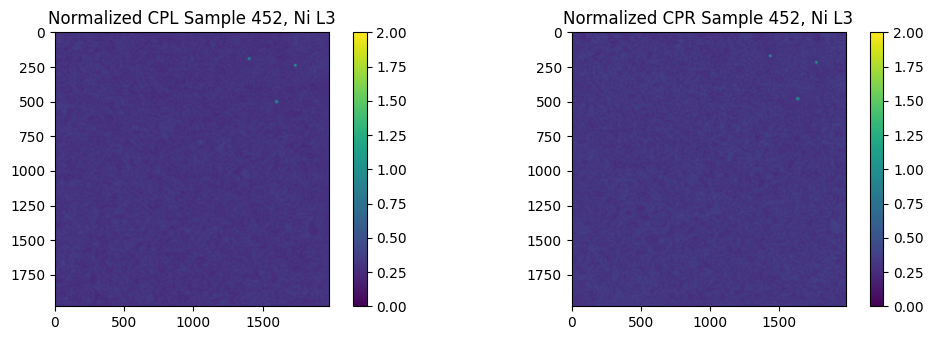

  Estimated translation: (-17.822731438520208, 30.081848305838463)


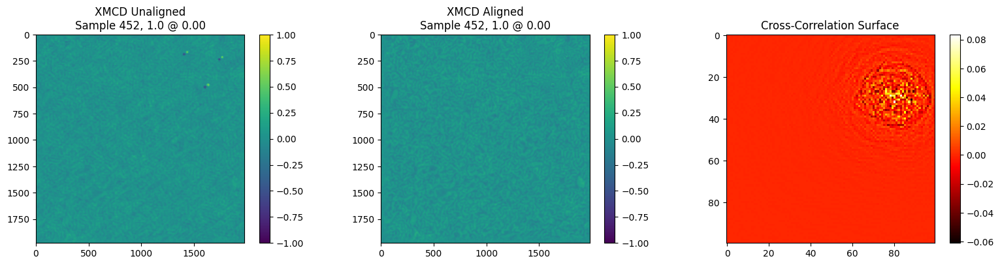

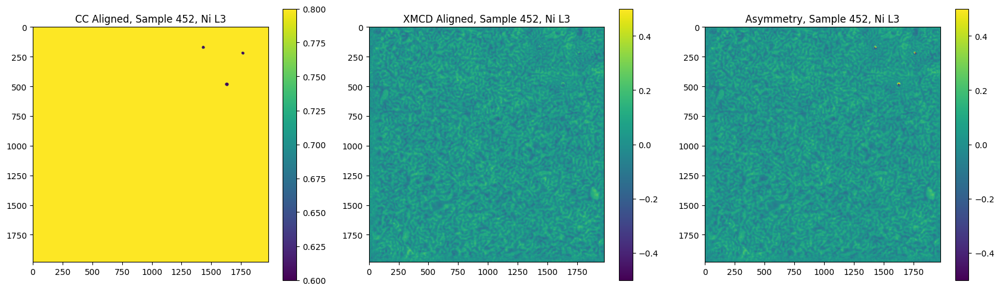

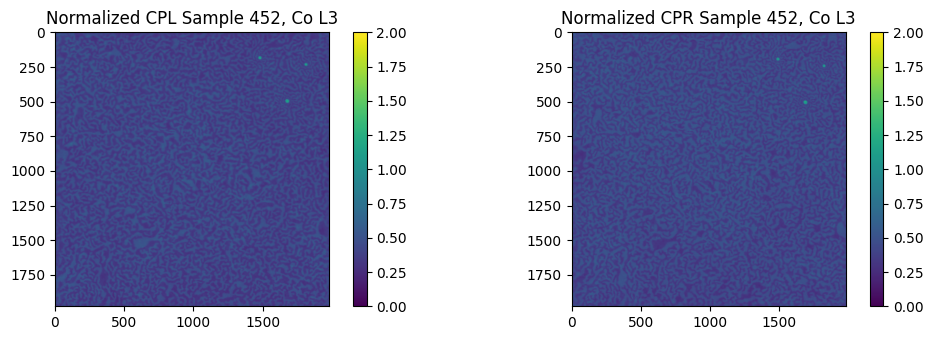

  Estimated translation: (9.218623238632063, 7.710370970467665)


/tmp/ipykernel_1043594/3963145796.py:155: RuntimeWarning: invalid value encountered in log10
  aligned_diffMap   = (-1 * np.log10(translated_neg)) - OD_pos


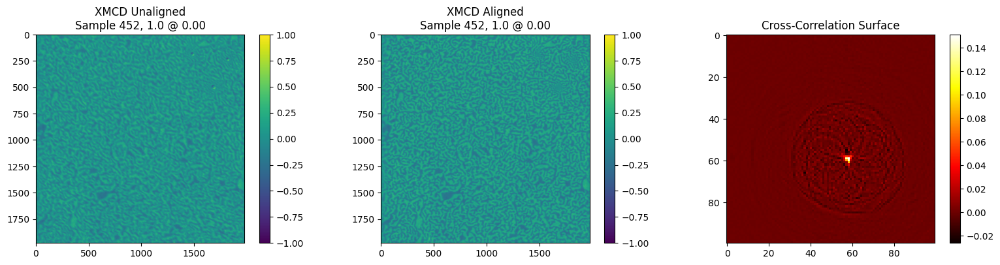

/tmp/ipykernel_1043594/3963145796.py:165: RuntimeWarning: invalid value encountered in log10
  CC_L = (-1 * np.log10(translated_neg)) + OD_pos
/tmp/ipykernel_1043594/3963145796.py:167: RuntimeWarning: invalid value encountered in log10
  cc = axes[0].imshow((-1 * np.log10(translated_neg)) + OD_pos,
/tmp/ipykernel_1043594/3963145796.py:172: RuntimeWarning: invalid value encountered in log10
  XMCD_L  = (-1 * np.log10(translated_neg)) - OD_pos
/tmp/ipykernel_1043594/3963145796.py:174: RuntimeWarning: invalid value encountered in log10
  xmcd = axes[1].imshow((-1 * np.log10(translated_neg)) - OD_pos,
/tmp/ipykernel_1043594/3963145796.py:179: RuntimeWarning: invalid value encountered in log10
  ASYM_L = ((-1 * np.log10(translated_neg)) - OD_pos)/((-1 * np.log10(translated_neg)) + OD_pos)
/tmp/ipykernel_1043594/3963145796.py:181: RuntimeWarning: invalid value encountered in log10
  asymm  = axes[2].imshow(((-1 * np.log10(translated_neg)) - OD_pos)/((-1 * np.log10(translated_neg)) + OD_pos),

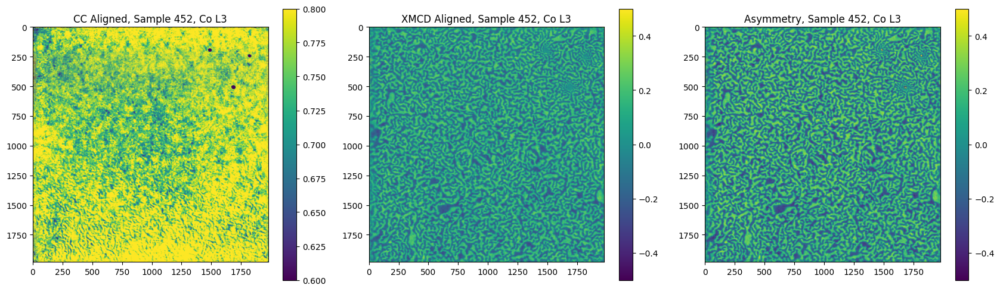

In [8]:
## plot a single scan, Raw CPL and CPR amplitude images
set_factor = 1.75
bound_preview = 50   


OD_neg_pol = []
OD_pos_pol = []

CC = []
XMCD = []
ASYM = []


translated_mask = []

for edge in np.arange(0, len(edges)): 
    img_neg = neg_pol[edge]
    img_pos = pos_pol[edge]

    colors = color_list[edge]
    angle = 0

    # 1. Raw amplitude images
    # norm_raw = mpl.colors.Normalize(vmin=np.min(img_neg), vmax=np.max(img_neg))
    # fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
    # CL = axes[0].imshow(img_neg, norm=norm_raw)
    # fig.colorbar(CL, ax=axes[0])
    # axes[0].set_title(f"CPL Sample {sample}, {edges[edge]} L3")
    # CR = axes[1].imshow(img_pos, norm=norm_raw)
    # fig.colorbar(CR, ax=axes[1])
    # axes[1].set_title(f"CPR Sample {sample}, {edges[edge]} L3")
    # plt.tight_layout(); plt.show()
    
    mean_CPL = np.mean(img_neg) 
    mean_CPR = np.mean(img_pos)
    
    # # 3. Intensity histograms (raw)
    # # register.plot_histogram(
    # #     img_neg.flatten(), img_pos.flatten(), bin_size,
    # #     color_neg, color_pos,
    # #     angle=angle, sample=sample, Gamma=Gamma, 
    # #     label1 = 'CPL', label2 = 'CPR', title='Raw amplitude'
    # # )
    
    label1 = 'CPL'
    label2 = 'CPR'
    title='Raw amplitude'
    
    # plt.figure()
    # plt.hist(img_neg.flatten(), bins=bin_size, color=colors[0], label=f'{label1}', alpha=0.7)
    # plt.hist(img_pos.flatten(), bins=bin_size, color=colors[1], label=f'{label2}', alpha=0.7)
    # plt.xlabel('Intensity')
    # plt.ylabel('Pixel Count')
    # plt.axvline(mean_CPR, color = colors[0], label = f'mean = {mean_CPR:.2f}')
    # plt.axvline(mean_CPL, color = colors[1], label = f'mean = {mean_CPL:.2f}')
    # # plt.ylim(0, 1000)
    # plt.legend()
    # plt.title(f"Sample {sample}, {edges[edge]} L3 \n{title}")
    # plt.tight_layout()
    # plt.show()


#################################################### Normalize ###################################################################

    # 4. Fiducial normalization
    norm_neg, fid_mean_neg, neg_px, masked_neg = register.auto_normalize_by_fiducial_kmeans(
        img_neg,
        fiduc_num=fiduc_num,
        factor=set_factor,
        plot=PLOT_FIDUCIAL_HIST,
        sample=sample,
        Gamma=Gamma
    )
    
    norm_pos, fid_mean_pos, pos_px, masked_pos = register.auto_normalize_by_fiducial_kmeans(
        img_pos,
        fiduc_num=fiduc_num,
        factor=set_factor,
        plot=PLOT_FIDUCIAL_HIST,
        sample=sample,
        Gamma=Gamma
    )
    
    
    # 1. normalized amplitude images
    norm_raw = mpl.colors.Normalize(vmin=0, vmax=2)
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
    CL = axes[0].imshow(norm_neg, norm=norm_raw)
    fig.colorbar(CL, ax=axes[0])
    axes[0].set_title(f"Normalized CPL Sample {sample}, {edges[edge]} L3")
    CR = axes[1].imshow(norm_pos, norm=norm_raw)
    fig.colorbar(CR, ax=axes[1])
    axes[1].set_title(f"Normalized CPR Sample {sample}, {edges[edge]} L3")
    plt.tight_layout(); plt.show()
    
    
    ########################################################## Optical Density ################################################################
    # # 5. Optical density
    OD_neg = -1 * np.log10(norm_neg)
    OD_pos = -1 * np.log10(norm_pos)

    OD_neg_pol.append(OD_neg)
    OD_pos_pol.append(OD_pos)    
    
    # norm_OD = mpl.colors.Normalize(vmin=np.min(OD_neg), vmax=np.max(OD_neg))
    # fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
    # CL = axes[0].imshow(OD_neg, norm=norm_OD)
    # fig.colorbar(CL, ax=axes[0])
    # axes[0].set_title(f"OD CPL normalized, Sample {sample}, {edges[edge]} L3")
    # CR = axes[1].imshow(OD_pos, norm=norm_OD)
    # fig.colorbar(CR, ax=axes[1])
    # axes[1].set_title(f"OD CPR normalized, Sample {sample}, {edges[edge]} L3")
    # plt.tight_layout(); plt.show()
    
    ############################################################ Cross Correlation ##############################################################
    # 7. Cross-correlation alignment
    translation, corr = register.align_images_CC(masked_pos, masked_neg, bound_preview)
    print(f"  Estimated translation: {translation}")
    
    f_target         = fftn(norm_neg)
    f_target_shifted = fourier_shift(f_target, translation)
    translated_neg   = ifftn(f_target_shifted).real
    
    ## shift mask to also compare 
    __, __, __, translated_neg_mask = register.auto_normalize_by_fiducial_kmeans(
        translated_neg, fiduc_num=fiduc_num, factor=set_factor,
        plot=False, sample=sample, Gamma=Gamma
    )

    translated_mask.append(translated_neg_mask)
    
    # # 6. Fiducial hole mask (binary)
    # # masked_pos, masked_neg = register.mask_holes_to_one(norm_pos, norm_neg, factor)
    # # Plot fiducial masks before and after CC
    # fig, axes = plt.subplots(1, 5, figsize=(21, 3.5))
    # axes[0].imshow(masked_pos, norm=mpl.colors.Normalize(vmin=-0.01, vmax=0.01))
    # axes[0].set_title(f"Masked CPR, \n Sample {sample}, {edges[edge]} L3")
    # axes[1].imshow(masked_neg, norm=mpl.colors.Normalize(vmin=-0.01, vmax=0.01))
    # axes[1].set_title(f"Masked CPL, \n Sample {sample}, {edges[edge]} L3")
    # diff = masked_neg.astype(int) - masked_pos.astype(int)
    # axes[2].imshow(diff, norm=mpl.colors.Normalize(vmin=-0.01, vmax=0.01))
    # axes[2].set_title(f"Masked CPL - CPR, \n Sample {sample}, {edges[edge]} L3")
    
    # axes[3].imshow(translated_neg_mask, norm=mpl.colors.Normalize(vmin=-0.01, vmax=0.01))
    # axes[3].set_title(f"translated masked CPL, \n Sample {sample}, {edges[edge]} L3")
    
    # diff_trans = translated_neg_mask.astype(int) - masked_pos.astype(int)
    # axes[4].imshow(diff_trans, norm=mpl.colors.Normalize(vmin=-0.01, vmax=0.01))
    # axes[4].set_title(f"Masked shifted CPL - CPR, \n Sample {sample}, {edges[edge]} L3")
    # plt.tight_layout(); plt.show()
    
    
    #### Look at the aligned vs unaligned XMCD ###
    unaligned_diffMap = OD_neg - OD_pos
    aligned_diffMap   = (-1 * np.log10(translated_neg)) - OD_pos
    
    register.plot_XMCD_crosscorr(
        unaligned_diffMap, aligned_diffMap, corr,
        angle=angle, sample=sample, Gamma=Gamma
    )
    
    # 8. Aligned charge contrast
    fig, axes = plt.subplots(1, 3, figsize=(17, 5))
    
    CC_L = (-1 * np.log10(translated_neg)) + OD_pos
    CC.append(CC_L)
    cc = axes[0].imshow((-1 * np.log10(translated_neg)) + OD_pos,
                norm=mpl.colors.Normalize(vmin=0.6, vmax=0.8)) ########################################
    axes[0].set_title(f"CC Aligned, Sample {sample}, {edges[edge]} L3")
    fig.colorbar(cc, ax=axes[0])
    
    XMCD_L  = (-1 * np.log10(translated_neg)) - OD_pos
    XMCD.append(XMCD_L)
    xmcd = axes[1].imshow((-1 * np.log10(translated_neg)) - OD_pos,
                norm=mpl.colors.Normalize(vmin=-0.5, vmax=0.5))
    axes[1].set_title(f"XMCD Aligned, Sample {sample}, {edges[edge]} L3")
    fig.colorbar(xmcd, ax=axes[1])
    
    ASYM_L = ((-1 * np.log10(translated_neg)) - OD_pos)/((-1 * np.log10(translated_neg)) + OD_pos)
    ASYM.append(ASYM_L)
    asymm  = axes[2].imshow(((-1 * np.log10(translated_neg)) - OD_pos)/((-1 * np.log10(translated_neg)) + OD_pos),
                norm=mpl.colors.Normalize(vmin=-0.5, vmax=0.5))
    axes[2].set_title(f"Asymmetry, Sample {sample}, {edges[edge]} L3")
    fig.colorbar(asymm, ax=axes[2])
    
    plt.tight_layout(); plt.show()

    



# normalize by pre-edge

In [4]:
# ============================================================
# Cell 3 — Parameters
# ============================================================
set_factor    = 1.75
bound_preview = 50
sample        = '452'        # whatever you already use
Gamma         = 1.0
fiduc_num     = 3
PLOT_FIDUCIAL_HIST = False

# Output containers
OD_neg_pol, OD_pos_pol           = [], []
OD_pre_neg_pol, OD_pre_pos_pol   = [], []

CC, XMCD, ASYM                   = [], [], []   # uncorrected (your originals)
XAS_map                          = []           # elemental map (edge jump)
XMCD_bg                          = []           # pre-edge-subtracted XMCD (OD)
ASYM_edgejump                    = []           # edge-jump-normalized asymmetry
FLUX_RATIO                       = []           # helicity flux ratio from pre-edge
translated_mask                  = []


[Ni] L3 shape = (1978, 1978), pre-edge shape = (400, 400)
[Ni] Pre-edge helicity flux ratio (neg/pos) = 1.0840
not dead
not dead


OpenBLAS warning: precompiled NUM_THREADS exceeded, adding auxiliary array for thread metadata.
To avoid this warning, please rebuild your copy of OpenBLAS with a larger NUM_THREADS setting
or set the environment variable OPENBLAS_NUM_THREADS to 64 or lower
/tmp/ipykernel_1047990/2306444335.py:53: RuntimeWarning: divide by zero encountered in log10
  OD_pre_pos = -np.log10(norm_pre_pos)


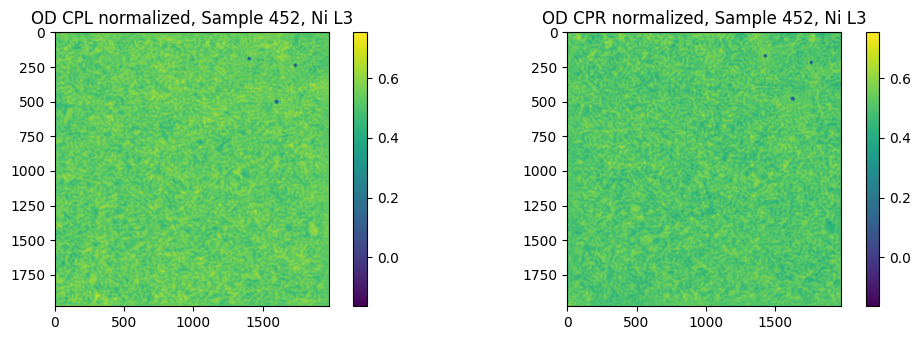

not dead
[Ni] Estimated translation (L3 only): (-17.822731438520208, 30.081848305838463)
[Ni] pre-edge OD baselines: neg=0.0000, pos=inf  (Δ=-inf)


TypeError: unsupported format string passed to numpy.ndarray.__format__

In [5]:
# ============================================================
# Cell 4 — Main loop: process L3 + pre-edge for each element
#          (scalar pre-edge baseline to handle STXM vs ptycho
#           pixel-grid mismatch)
# ============================================================
for edge in range(len(edges)):
    elem  = edges[edge]
    colors = color_list[edge]

    # -------- raw images --------
    img_neg = neg_pol[edge]
    img_pos = pos_pol[edge]
    pre_n   = pre_neg[edge]
    pre_p   = pre_pos[edge]

    print(f"\n[{elem}] L3 shape = {img_neg.shape}, pre-edge shape = {pre_n.shape}")

    # =========================================================
    # 1. Flux ratio between helicities (from pre-edge means)
    #    Pre-edge contains no XMCD, so any mean difference
    #    between +/- helicity here is instrumental.
    # =========================================================
    R_flux = np.mean(pre_n) / np.mean(pre_p)
    FLUX_RATIO.append(R_flux)
    print(f"[{elem}] Pre-edge helicity flux ratio (neg/pos) = {R_flux:.4f}")

    # =========================================================
    # 2. Normalize each image by its fiducial (your existing
    #    pipeline) — both L3 and pre-edge.
    # =========================================================
    print('not dead')
    norm_neg, _, _, masked_neg = register.auto_normalize_by_fiducial_kmeans(
        img_neg, fiduc_num=fiduc_num, factor=set_factor,
        plot=PLOT_FIDUCIAL_HIST, sample=sample, Gamma=Gamma)
    norm_pos, _, _, masked_pos = register.auto_normalize_by_fiducial_kmeans(
        img_pos, fiduc_num=fiduc_num, factor=set_factor,
        plot=PLOT_FIDUCIAL_HIST, sample=sample, Gamma=Gamma)

    print('not dead')
    norm_pre_neg, _, _, _ = register.auto_normalize_by_fiducial_kmeans(
        pre_n, fiduc_num=fiduc_num, factor=set_factor,
        plot=False, sample=sample, Gamma=Gamma)
    norm_pre_pos, _, _, _ = register.auto_normalize_by_fiducial_kmeans(
        pre_p, fiduc_num=fiduc_num, factor=set_factor,
        plot=False, sample=sample, Gamma=Gamma)

    # =========================================================
    # 3. Optical density for all four images
    # =========================================================
    OD_neg     = -np.log10(norm_neg)
    OD_pos     = -np.log10(norm_pos)
    OD_pre_neg = -np.log10(norm_pre_neg)
    OD_pre_pos = -np.log10(norm_pre_pos)


    norm_OD = mpl.colors.Normalize(vmin=np.min(OD_neg), vmax=np.max(OD_neg))
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
    CL = axes[0].imshow(OD_neg, norm=norm_OD)
    fig.colorbar(CL, ax=axes[0])
    axes[0].set_title(f"OD CPL normalized, Sample {sample}, {edges[edge]} L3")
    CR = axes[1].imshow(OD_pos, norm=norm_OD)
    fig.colorbar(CR, ax=axes[1])
    axes[1].set_title(f"OD CPR normalized, Sample {sample}, {edges[edge]} L3")
    plt.tight_layout(); plt.show()

    
    print('not dead')
    OD_neg_pol.append(OD_neg);     OD_pos_pol.append(OD_pos)
    OD_pre_neg_pol.append(OD_pre_neg); OD_pre_pos_pol.append(OD_pre_pos)

    # =========================================================
    # 4. Cross-correlation alignment of CPL onto CPR at L3.
    #    NOTE: pre-edge is on a different pixel grid (STXM vs
    #    ptycho) so we cannot apply the same shift directly.
    #    We collapse it to a scalar baseline instead (Section 5).
    # =========================================================
    translation, corr = register.align_images_CC(masked_pos, masked_neg, bound_preview)
    print(f"[{elem}] Estimated translation (L3 only): {translation}")

    def shift_image(im, shift):
        f = fftn(im)
        return ifftn(fourier_shift(f, shift)).real

    translated_neg = shift_image(norm_neg, translation)
    OD_neg_al      = -np.log10(translated_neg)

    # For the mask record (your existing tracking)
    _, _, _, translated_neg_mask = register.auto_normalize_by_fiducial_kmeans(
        translated_neg, fiduc_num=fiduc_num, factor=set_factor,
        plot=False, sample=sample, Gamma=Gamma)
    translated_mask.append(translated_neg_mask)

    # =========================================================
    # 5. Pre-edge-corrected resonant OD
    #    Because the pre-edge (STXM) and L3 (ptycho) images have
    #    different pixel grids, we use the spatial MEAN of the
    #    pre-edge OD as a scalar baseline. This still removes
    #    helicity-dependent baseline offsets and lets us define
    #    a meaningful edge-jump map and asymmetry.
    # =========================================================
    pre_neg_level = np.nanmean(OD_pre_neg)
    pre_pos_level = np.nanmean(OD_pre_pos)
    print(f"[{elem}] pre-edge OD baselines: neg={pre_neg_level:.4f}, "
          f"pos={pre_pos_level:.4f}  (Δ={pre_neg_level-pre_pos_level:+.4f})")

    OD_neg_res = OD_neg_al - pre_neg_level
    OD_pos_res = OD_pos    - pre_pos_level

    print(f"[{elem}] subtracted OD baselines: neg={OD_neg_res:.4f}, "
          f"pos={OD_pos_res:.4f}")

    # ----- (a) Original (uncorrected) quantities, your code -----
    CC_L   = OD_neg_al + OD_pos
    XMCD_L = OD_neg_al - OD_pos
    ASYM_L = XMCD_L / CC_L
    CC.append(CC_L); XMCD.append(XMCD_L); ASYM.append(ASYM_L)

    # ----- (b) Pre-edge subtracted XMCD (resonant only) -----
    #     Note: since the pre-edge correction is a scalar per
    #     helicity, the *spatial structure* of XMCD_bg_L is the
    #     same as XMCD_L; what changes is its overall offset,
    #     which corrects for helicity flux imbalance.
    XMCD_bg_L = OD_neg_res - OD_pos_res
    XMCD_bg.append(XMCD_bg_L)

    # ----- (c) XAS / elemental edge-jump map -----
    XAS_L = 0.5 * (OD_neg_res + OD_pos_res)
    XAS_map.append(XAS_L)

    # ----- (d) Edge-jump normalized asymmetry -----
    denom = 2.0 * gaussian_filter(XAS_L, sigma=1.0)
    # mask where edge jump is tiny (no magnetic element / membrane only)
    edge_thresh = 0.05 * np.nanmax(XAS_L)
    mask_valid  = (XAS_L > edge_thresh) & (np.abs(denom) > 1e-6)
    ASYM_ej = np.where(mask_valid, XMCD_bg_L / denom, np.nan)
    ASYM_edgejump.append(ASYM_ej)

    # =========================================================
    # 6. Plot everything side by side for this element
    # =========================================================
    fig, axes = plt.subplots(2, 3, figsize=(17, 9))

    # --- top row: the three "use the pre-edge" products ---
    im0 = axes[0,0].imshow(XAS_L,
            norm=mpl.colors.Normalize(vmin=0, vmax=np.nanpercentile(XAS_L, 99)))
    axes[0,0].set_title(f"{elem} XAS edge-jump map\n"
                        f"½·(OD⁺+OD⁻) − ½·(pre⁺+pre⁻)")
    fig.colorbar(im0, ax=axes[0,0])

    im1 = axes[0,1].imshow(XMCD_bg_L,
            norm=mpl.colors.Normalize(vmin=-0.5, vmax=0.5), cmap='RdBu_r')
    axes[0,1].set_title(f"{elem} XMCD (pre-edge baseline subtracted)")
    fig.colorbar(im1, ax=axes[0,1])

    im2 = axes[0,2].imshow(ASYM_ej,
            norm=mpl.colors.Normalize(vmin=-0.5, vmax=0.5), cmap='RdBu_r')
    axes[0,2].set_title(f"{elem} edge-jump normalized asymmetry\n"
                        f"flux ratio = {R_flux:.3f}")
    fig.colorbar(im2, ax=axes[0,2])

    # --- bottom row: your original (no pre-edge) for comparison ---
    im3 = axes[1,0].imshow(CC_L,
            norm=mpl.colors.Normalize(vmin=0.6, vmax=0.8))
    axes[1,0].set_title(f"{elem} CC (no pre-edge)\nOD⁻ + OD⁺")
    fig.colorbar(im3, ax=axes[1,0])

    im4 = axes[1,1].imshow(XMCD_L,
            norm=mpl.colors.Normalize(vmin=-0.5, vmax=0.5), cmap='RdBu_r')
    axes[1,1].set_title(f"{elem} XMCD (no pre-edge)\nOD⁻ − OD⁺")
    fig.colorbar(im4, ax=axes[1,1])

    im5 = axes[1,2].imshow(ASYM_L,
            norm=mpl.colors.Normalize(vmin=-0.5, vmax=0.5), cmap='RdBu_r')
    axes[1,2].set_title(f"{elem} Asymmetry (no pre-edge)\n(OD⁻−OD⁺)/(OD⁻+OD⁺)")
    fig.colorbar(im5, ax=axes[1,2])

    for ax in axes.ravel():
        ax.set_xticks([]); ax.set_yticks([])

    plt.suptitle(f"Sample {sample}, {elem} L3 — pre-edge analysis comparison",
                 fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()

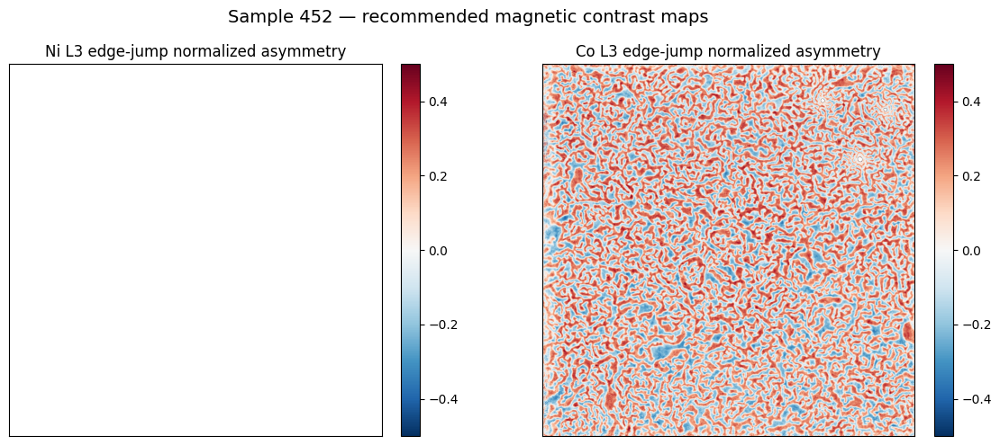

In [6]:
# ============================================================
# Cell 5 — Side-by-side Co vs Ni summary figure
#          (edge-jump normalized asymmetry — the recommended map)
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for i, elem in enumerate(edges):
    im = axes[i].imshow(ASYM_edgejump[i],
            norm=mpl.colors.Normalize(vmin=-0.5, vmax=0.5), cmap='RdBu_r')
    axes[i].set_title(f"{elem} L3 edge-jump normalized asymmetry")
    axes[i].set_xticks([]); axes[i].set_yticks([])
    fig.colorbar(im, ax=axes[i], fraction=0.046, pad=0.04)
plt.suptitle(f"Sample {sample} — recommended magnetic contrast maps", fontsize=14)
plt.tight_layout()
plt.show()

ValueError: supplied range of [inf, inf] is not finite

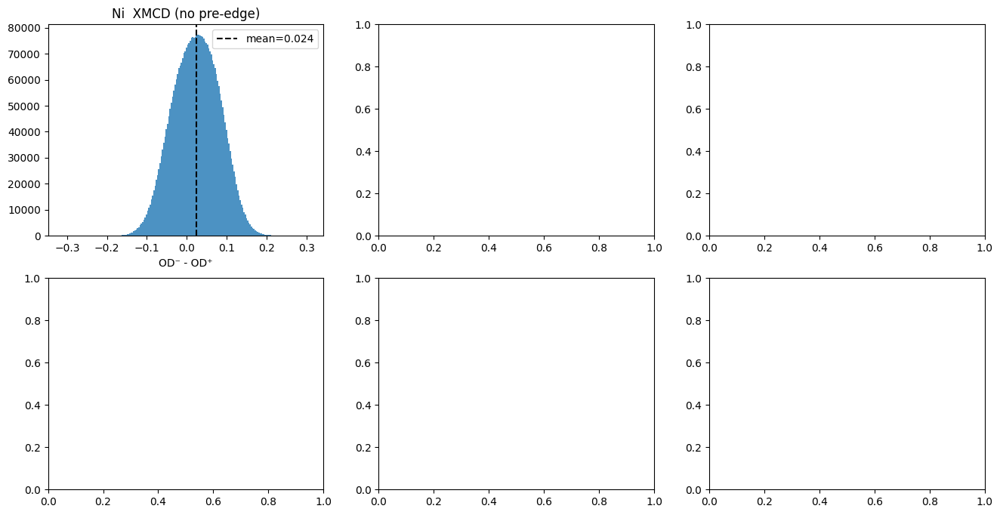

In [7]:
# ============================================================
# Cell 6 — Histograms of each XMCD flavor for Co and Ni
#          (helps you see how pre-edge correction tightens/centers
#           the distribution and removes baseline offsets)
# ============================================================
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for i, elem in enumerate(edges):
    c = color_list[i][2]

    # raw XMCD (your original)
    axes[i,0].hist(XMCD[i].ravel(), bins=200, color=c, alpha=0.8)
    axes[i,0].axvline(np.nanmean(XMCD[i]), color='k', ls='--',
                      label=f"mean={np.nanmean(XMCD[i]):.3f}")
    axes[i,0].set_title(f"{elem}  XMCD (no pre-edge)")
    axes[i,0].set_xlabel("OD⁻ - OD⁺"); axes[i,0].legend()

    # pre-edge subtracted XMCD
    axes[i,1].hist(XMCD_bg[i].ravel(), bins=200, color=c, alpha=0.8)
    axes[i,1].axvline(np.nanmean(XMCD_bg[i]), color='k', ls='--',
                      label=f"mean={np.nanmean(XMCD_bg[i]):.3f}")
    axes[i,1].set_title(f"{elem}  XMCD (pre-edge subtracted)")
    axes[i,1].set_xlabel("(OD⁻−pre⁻) − (OD⁺−pre⁺)"); axes[i,1].legend()

    # edge-jump normalized asymmetry
    vals = ASYM_edgejump[i].ravel()
    vals = vals[np.isfinite(vals)]
    axes[i,2].hist(vals, bins=200, color=c, alpha=0.8)
    axes[i,2].axvline(np.nanmean(vals), color='k', ls='--',
                      label=f"mean={np.nanmean(vals):.3f}")
    axes[i,2].set_title(f"{elem}  Edge-jump normalized asymmetry")
    axes[i,2].set_xlabel("XMCD_res / edge-jump"); axes[i,2].legend()

plt.suptitle(f"Sample {sample} — distributions across pre-edge processing flavors",
             fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# Cell 7 — Quick numerical summary
# ============================================================
print(f"{'Element':<8}{'Flux ratio':>12}{'⟨XMCD⟩':>14}"
      f"{'⟨XMCD_res⟩':>14}{'⟨Asym_ej⟩':>14}{'σ(Asym_ej)':>14}")
print("-" * 76)
for i, elem in enumerate(edges):
    aej = ASYM_edgejump[i]
    aej = aej[np.isfinite(aej)]
    print(f"{elem:<8}{FLUX_RATIO[i]:>12.4f}"
          f"{np.nanmean(XMCD[i]):>14.4f}"
          f"{np.nanmean(XMCD_bg[i]):>14.4f}"
          f"{np.nanmean(aej):>14.4f}"
          f"{np.nanstd(aej):>14.4f}")

---
## Step 6 — mask and compare domain pattern 



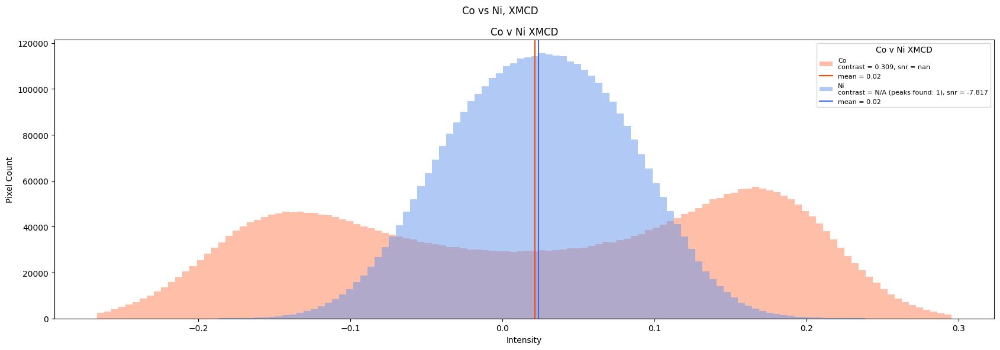

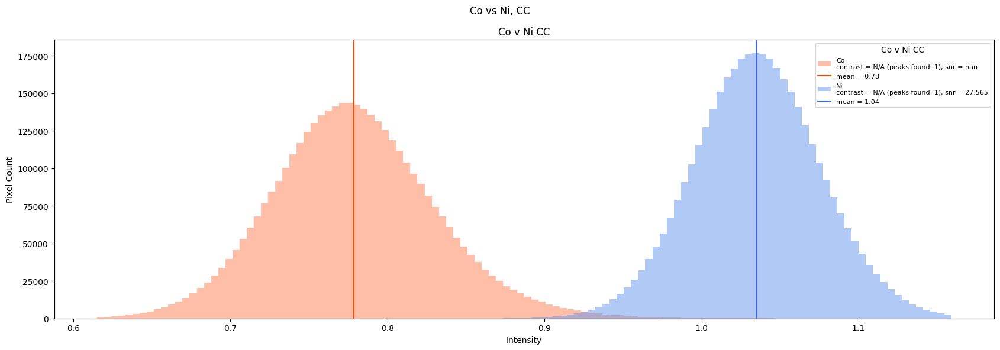

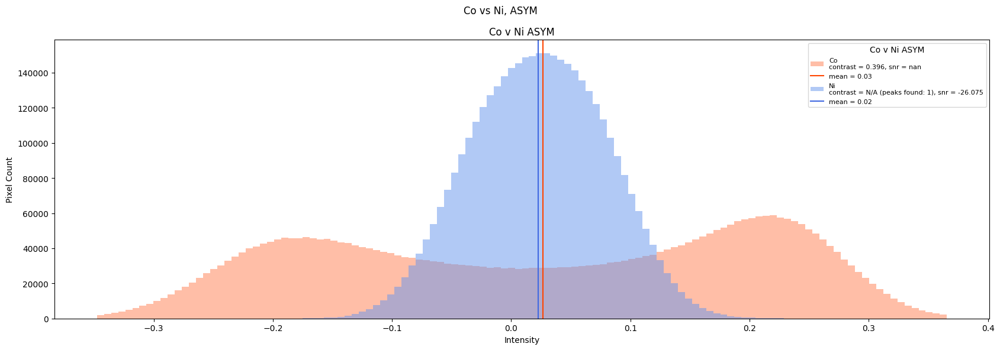

In [5]:
compare_dict = {
    "Co v Ni XMCD": {
        "Co": XMCD[1],
        "Ni": XMCD[0],
    }
}

hist_colors = {
    "Co": color_list[1][0], 
    "Ni": color_list[0][0],  
}

mean_line_colors = {
    "Co":  color_list[1][1],   # or color_pos
    "Ni": color_list[0][1],      # or color_neg
}

register.plot_hist_compare_dict(
    compare_dict=compare_dict,
    bins=120,
    robust_range_pct=(0.1, 99.9),
    shared_range=True,
    report_clipped=True,
    use_safe_peak_contrast=True,   # <- your requested behavior
    peak_prominence=None,          # or set e.g. 200
    peak_distance=5,
    figsize=(17, 6),
    show_mean_lines=True, 
    hist_colors=hist_colors,
    mean_line_colors=mean_line_colors,
    suptitle="Co vs Ni, XMCD"
)

compare_dict = {
    "Co v Ni CC": {
        "Co": CC[1],
        "Ni": CC[0],
    }
}

hist_colors = {
    "Co": color_list[1][0], 
    "Ni": color_list[0][0],  
}

mean_line_colors = {
    "Co":  color_list[1][1],   # or color_pos
    "Ni": color_list[0][1],      # or color_neg
}

register.plot_hist_compare_dict(
    compare_dict=compare_dict,
    bins=120,
    robust_range_pct=(0.1, 99.9),
    shared_range=True,
    report_clipped=True,
    use_safe_peak_contrast=True,   # <- your requested behavior
    peak_prominence=None,          # or set e.g. 200
    peak_distance=5,
    figsize=(17, 6),
    show_mean_lines=True, 
    hist_colors=hist_colors,
    mean_line_colors=mean_line_colors,
    suptitle="Co vs Ni, CC"
)

compare_dict = {
    "Co v Ni ASYM": {
        "Co": ASYM[1],
        "Ni": ASYM[0],
    }
}

hist_colors = {
    "Co": color_list[1][0], 
    "Ni": color_list[0][0],  
}

mean_line_colors = {
    "Co":  color_list[1][1],   # or color_pos
    "Ni": color_list[0][1],      # or color_neg
}

register.plot_hist_compare_dict(
    compare_dict=compare_dict,
    bins=120,
    robust_range_pct=(0.1, 99.9),
    shared_range=True,
    report_clipped=True,
    use_safe_peak_contrast=True,   # <- your requested behavior
    peak_prominence=None,          # or set e.g. 200
    peak_distance=5,
    figsize=(17, 6),
    show_mean_lines=True, 
    hist_colors=hist_colors,
    mean_line_colors=mean_line_colors,
    suptitle="Co vs Ni, ASYM"
)

# Create Mask and subtract 

  Estimated translation: (24.289033615673617, 61.32083696590192)


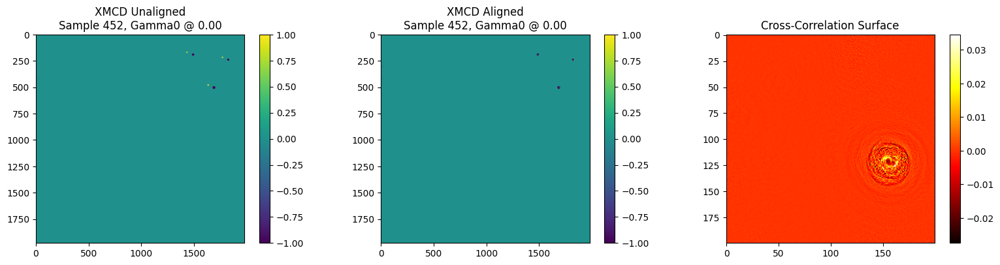

In [6]:
# register Co and Ni
## plot a single scan, Raw CPL and CPR amplitude images
set_factor = 1.8
bound_preview = 100   

translated_mask_Ni = translated_mask[0]
translated_mask_Co = translated_mask[1]
translated_mask_Ni = translated_mask_Ni.astype(int)
translated_mask_Co = translated_mask_Co.astype(int)

############################################################ Cross Correlation ##############################################################
# 7. Cross-correlation alignment
translation, corr = register.align_images_CC(translated_mask_Co, translated_mask_Ni, bound_preview)
print(f"  Estimated translation: {translation}")

f_target         = fftn(XMCD[0])
f_target_shifted = fourier_shift(f_target, translation)
aligned_Ni_XMCD   = ifftn(f_target_shifted).real

f_target         = fftn(CC[0])
f_target_shifted = fourier_shift(f_target, translation)
aligned_Ni_CC   = ifftn(f_target_shifted).real

f_target         = fftn(ASYM[0])
f_target_shifted = fourier_shift(f_target, translation)
aligned_Ni_ASYM   = ifftn(f_target_shifted).real


f_target         = fftn(translated_mask_Ni)
f_target_shifted = fourier_shift(f_target, translation)
aligned_Ni_mask   = ifftn(f_target_shifted).real


## shift mask to also compare 
# __, __, __, aligned_Ni_mask = register.auto_normalize_by_fiducial_kmeans(
#     aligned_Ni_XMCD, fiduc_num=fiduc_num, factor=set_factor,
#     plot=False, sample=sample, Gamma=Gamma
# )


translated_mask_Ni = translated_mask_Ni.astype(int)
translated_mask_Co = translated_mask_Co.astype(int)
aligned_Ni_mask = aligned_Ni_mask.astype(int)


#### Look at the aligned vs unaligned XMCD ###
unaligned_diffMap = translated_mask_Ni - translated_mask_Co
aligned_diffMap = aligned_Ni_mask - translated_mask_Co

register.plot_XMCD_crosscorr(
    unaligned_diffMap, aligned_diffMap, corr,
    angle=angle, sample=sample, Gamma=Gamma
)


aligned_XMCD = [aligned_Ni_XMCD, XMCD[1]]
aligned_CC = [aligned_Ni_XMCD, CC[1]]
aligned_ASYM = [aligned_Ni_XMCD, ASYM[1]]
aligned_mask = [aligned_Ni_mask, translated_mask[1]]


In [20]:
# mask and subtract

def mask_domains(image, threshold, plot=False, sample='', Gamma=''):
    """
    Apply a simple threshold to an image to produce a binary domain mask.

    Parameters
    ----------
    image     : 2D np.ndarray  — input image (float, may contain NaN/inf)
    threshold : float          — pixels above this value → 1 (up domain)
                                 pixels at or below    → 0 (down domain)
    plot      : bool           — if True, show the binary mask
    sample    : str            — plot title string (optional)
    Gamma     : str            — plot title string (optional)

    Returns
    -------
    mask_img  : 2D np.ndarray (int, same shape as image)
                1 = up domain, 0 = down domain, NaN/inf pixels → 0
    """
    # --- Step 1: binary threshold -------------------------------------------
    mask_img = np.where(np.isfinite(image) & (image > threshold), 1, 0).astype(int)

    # --- Step 2: optional plot ----------------------------------------------
    if plot:
        fig, ax = plt.subplots(1, 1, figsize=(12, 5))
        cmap = mpl.colors.ListedColormap(['steelblue', 'limegreen'])
        norm = mpl.colors.BoundaryNorm([0, 0.5, 1], ncolors=2)
        show = ax.imshow(mask_img, cmap=cmap, norm=norm)
        cbar = fig.colorbar(show, ax=ax, ticks=[0.25, 0.75])
        cbar.ax.set_yticklabels(['0 — down domain', '1 — up domain'])
        ax.set_title(f"Binary domain mask\n{sample}  {Gamma}")
        plt.tight_layout()
        plt.show()

    return mask_img

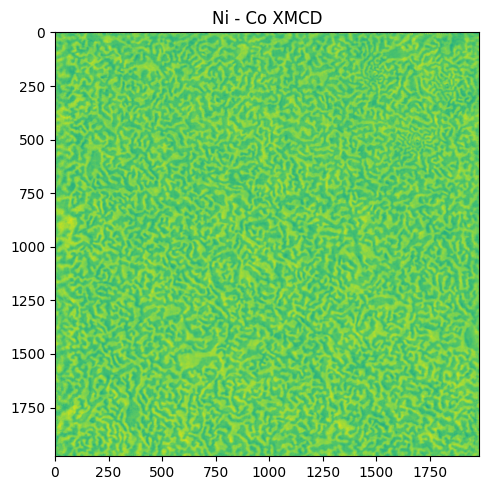

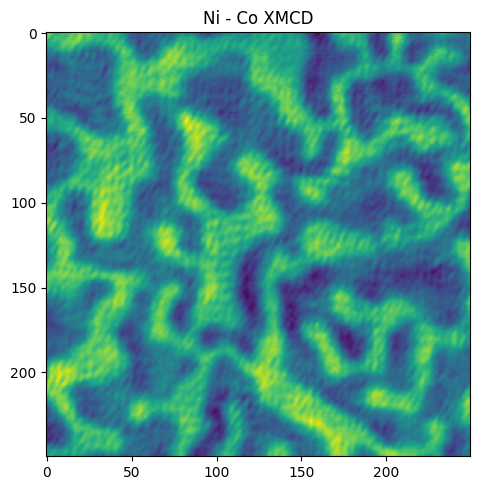

In [37]:
fig, ax = plt.subplots(1, 1, figsize=(12, 5))
show = ax.imshow(aligned_XMCD[0]-aligned_XMCD[1])
ax.set_title(f"Ni - Co XMCD")
plt.tight_layout()
plt.show()

Ni_crop_raw = (aligned_XMCD[0])[750:1000, 750:1000]
Co_crop_raw = (aligned_XMCD[1])[750:1000, 750:1000]

fig, ax = plt.subplots(1, 1, figsize=(12, 5))
show = ax.imshow(Ni_crop_raw-Co_crop_raw)
ax.set_title(f"Ni - Co XMCD")
plt.tight_layout()
plt.show()


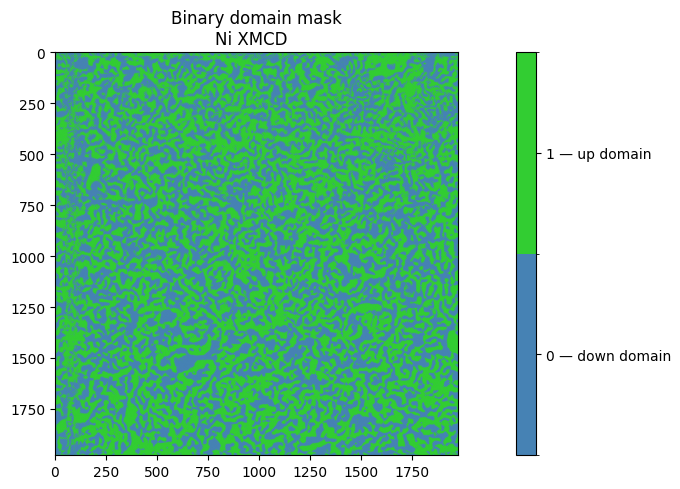

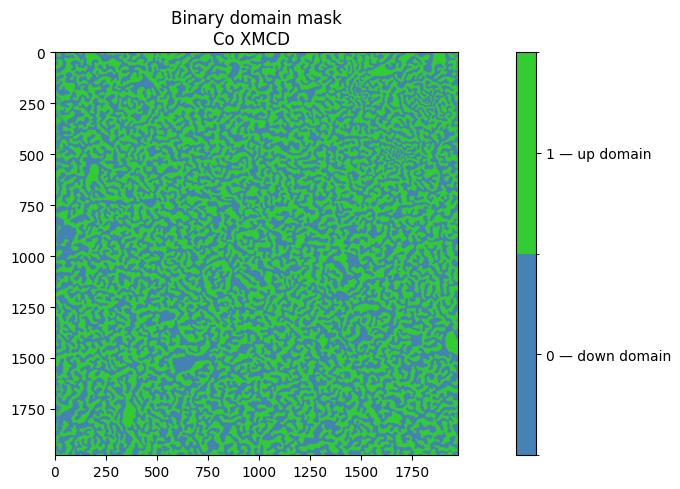

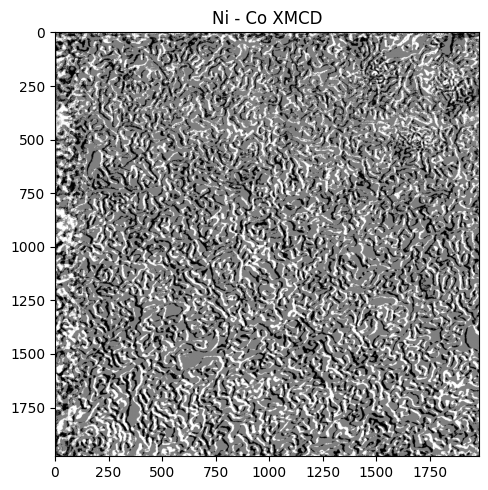

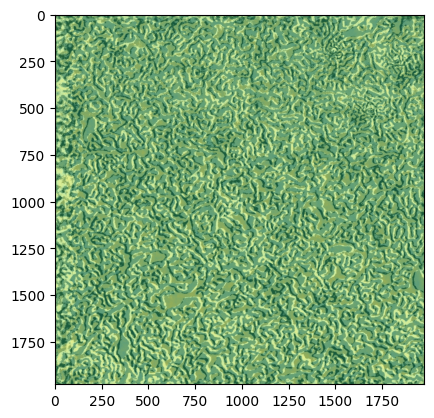

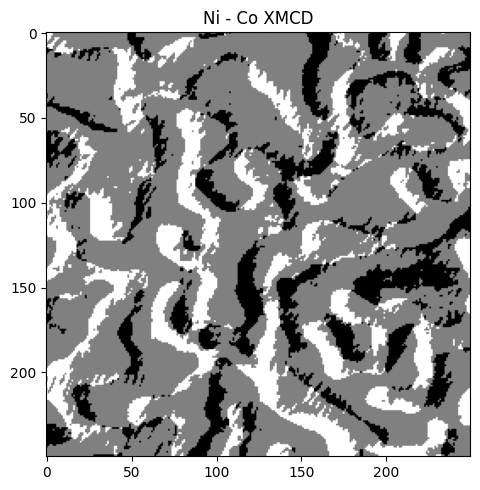

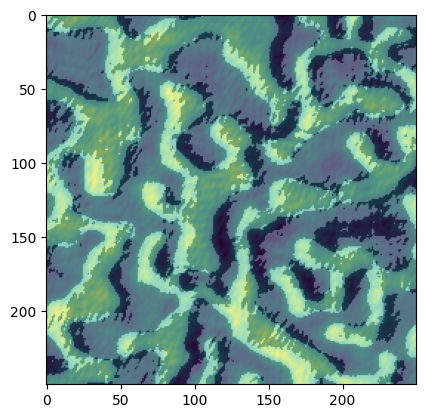

In [47]:
XMCD_Ni_mask = mask_domains(aligned_XMCD[0], 0.02, plot=True, sample='Ni XMCD', Gamma='')
XMCD_Co_mask = mask_domains(aligned_XMCD[1], 0.02, plot=True, sample='Co XMCD', Gamma='')

fig, ax = plt.subplots(1, 1, figsize=(12, 5))
show = ax.imshow(XMCD_Ni_mask-XMCD_Co_mask, cmap='gray')
ax.set_title(f"Ni - Co XMCD")
plt.tight_layout()
plt.show()


fig, ax = plt.subplots()

ax.imshow(aligned_XMCD[0]-aligned_XMCD[1])
ax.imshow(XMCD_Ni_mask-XMCD_Co_mask, cmap='gray', alpha=0.5)  # adjust alpha for opacity

plt.show()

Ni_crop = XMCD_Ni_mask[750:1000, 750:1000]
Co_crop = XMCD_Co_mask[750:1000, 750:1000]

fig, ax = plt.subplots(1, 1, figsize=(12, 5))
show = ax.imshow(Ni_crop-Co_crop,cmap='gray')
ax.set_title(f"Ni - Co XMCD")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots()

ax.imshow(Ni_crop_raw-Co_crop_raw)
ax.imshow(Ni_crop-Co_crop, cmap='gray', alpha=0.5)  # adjust alpha for opacity

plt.show()

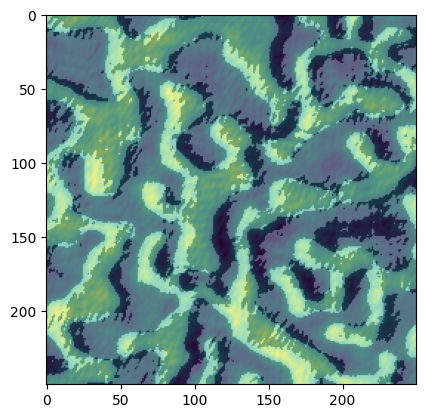

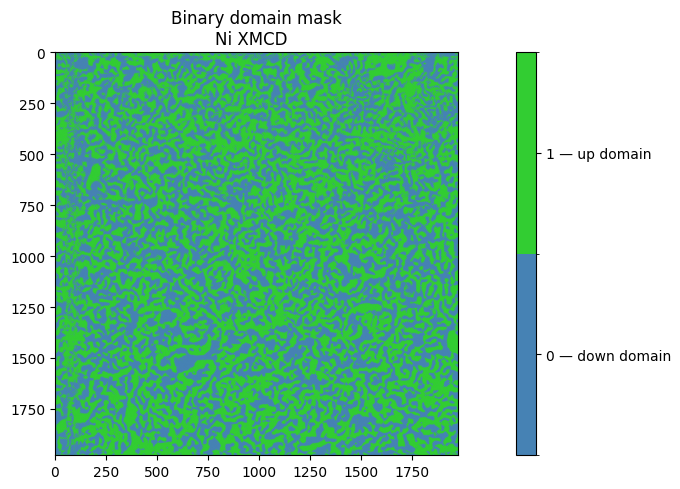

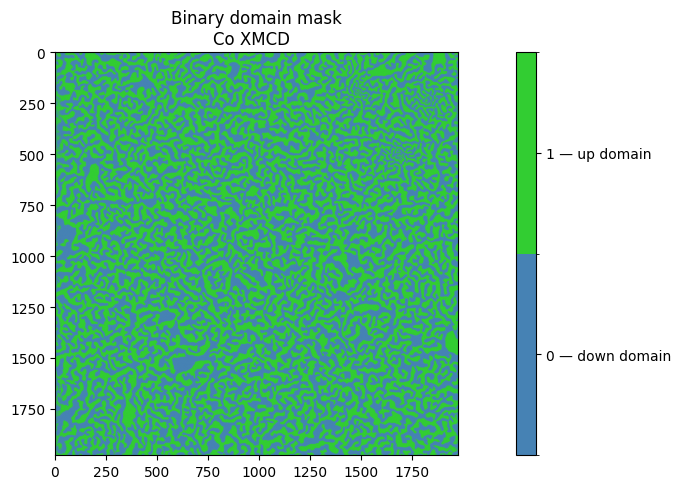

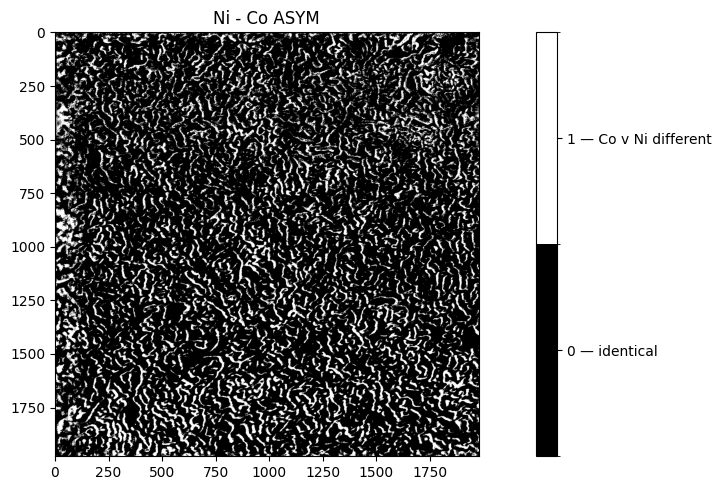

In [25]:
ASYM_Ni_mask = mask_domains(aligned_ASYM[0], 0.02, plot=True, sample='Ni XMCD', Gamma='')
ASYM_Co_mask = mask_domains(aligned_ASYM[1], 0.03, plot=True, sample='Co XMCD', Gamma='')

fig, ax = plt.subplots(1, 1, figsize=(12, 5))
cmap = mpl.colors.ListedColormap(['black', 'white'])
norm = mpl.colors.BoundaryNorm([0, 0.5, 1], ncolors=2)
show = ax.imshow(ASYM_Ni_mask-ASYM_Co_mask, cmap=cmap, norm=norm)
cbar = fig.colorbar(show, ax=ax, ticks=[0.25, 0.75])
cbar.ax.set_yticklabels(['0 — identical', '1 — Co v Ni different'])
ax.set_title(f"Ni - Co ASYM")
plt.tight_layout()
plt.show()

In [ ]:
masks = [(mask_img == i).astype(int) for i in range(fiduc_num)]

In [ ]:
n_scans = image_stack_pospol.shape[0]
# --- Initialize output arrays ------------------------------------------------
translated_negpol    = np.zeros_like(image_stack_negpol, dtype=np.float32)
norm_pos_OD          = np.zeros_like(image_stack_pospol, dtype=np.float32)
norm_neg_OD          = np.zeros_like(image_stack_negpol, dtype=np.float32)
unaligned_error_norm = np.empty(n_scans)
aligned_error_norm   = np.empty(n_scans)

# --- Main alignment loop -----------------------------------------------------
for k in range(n_scans):
    angle = angles_pospol[k]
    print(f"--- Scan {k:3d}/{n_scans-1} | angle={angle:.2f} ---")

    # 6a. Normalize each image to its fiducial mean intensity
    ## Max peak method... old. delete if kmeans works
    # norm_neg, fid_avg_neg = register.auto_normalize_by_fiducial(
    #     image_stack_negpol[k], color_neg, plot_hist=PLOT_FIDUCIAL_HIST
    # )
    # norm_pos, fid_avg_pos = register.auto_normalize_by_fiducial(
    #     image_stack_pospol[k], color_pos, plot_hist=PLOT_FIDUCIAL_HIST
    # )

    ## k means normalization
    norm_neg, __, ___,  masked_neg = register.auto_normalize_by_fiducial_kmeans(
        image_stack_negpol[k],
        fiduc_num=fiduc_num,
        factor=set_factor,
        plot=False,
        sample=sample,
        Gamma=Gamma
    )
    
    norm_pos, ___, ___, masked_pos = register.auto_normalize_by_fiducial_kmeans(
        image_stack_pospol[k],
        fiduc_num=fiduc_num,
        factor=set_factor,
        plot=False,
        sample=sample,
        Gamma=Gamma
    )
    
    # # 6b. Create binary fiducial hole mask for cross-correlation
    # masked_pos, masked_neg = register.mask_holes_to_one(norm_pos, norm_neg, factor)

    # 6c. Compute phase cross-correlation and estimate translation
    translation, corr = register.align_images_CC(masked_pos, masked_neg, bound)

    # 6d. Apply Fourier-domain shift to the normalized negative image
    f_target             = fftn(norm_neg)
    f_target_shifted     = fourier_shift(f_target, translation)
    translated_negpol_OD = ifftn(f_target_shifted).real

    # 6e. Convert amplitude -> optical density (OD = -ln(normalized amplitude))
    norm_pos_OD[k]       = -1 * np.log(norm_pos)
    norm_neg_OD[k]       = -1 * np.log(norm_neg)
    translated_negpol[k] = -1 * np.log(translated_negpol_OD)

    # 6f. Compute NRMSE before and after alignment as a quality metric
    unaligned_error_norm[k] = register.calc_NRMSE(
        image_stack_negpol[k], image_stack_pospol[k]
    )
    aligned_error_norm[k] = register.calc_NRMSE(
        translated_negpol[k], norm_pos_OD[k]
    )
    print(f"  NRMSE: before={unaligned_error_norm[k]*100:.2f}%  "
          f"after={aligned_error_norm[k]*100:.2f}%")

    # Optional: show before/after XMCD and cross-correlation surface
    if PLOT_CROSSCORR:
        unaligned_diff = norm_neg_OD[k] - norm_pos_OD[k]
        aligned_diff   = translated_negpol[k] - norm_pos_OD[k]
        register.plot_XMCD_crosscorr(
            unaligned_diff, aligned_diff, corr,
            angle=angle, sample=sample, Gamma=Gamma
        )

print("\nBatch alignment complete.")

---
## Step 8 — Compute Charge Contrast and XMCD Stacks

In [ ]:
# Charge contrast (CC) = OD_pos + OD_neg_aligned
OD_chrgcntrst = norm_pos_OD + translated_negpol 

# XMCD = OD_neg_aligned - OD_pos
OD_XMCD = translated_negpol - norm_pos_OD

# Unaligned versions retained for comparison in quality-check steps
CC_unaligned   = image_stack_negpol + image_stack_pospol
XMCD_unaligned = image_stack_negpol - image_stack_pospol

CC_unaligned_OD = norm_pos_OD + norm_neg_OD

print(f"OD_chrgcntrst shape: {OD_chrgcntrst.shape}")
print(f"OD_XMCD shape      : {OD_XMCD.shape}")

---
## Step 9 — Review All Scans: XMCD and Charge Contrast

Plots normalized CC and XMCD side-by-side for every scan.
Use this to visually identify outliers before the PSD quality check.

In [ ]:
for k in range(image_stack_pospol.shape[0]):
    angle = angles_pospol[k]
    register.plot_XMCD_CC_normalizeCC(
        OD_XMCD[k], OD_chrgcntrst[k],
        angle=angle, sample=sample, Gamma=Gamma
    )

---
## Step 11 — Regional Variance and PSD Quality Check

### 11a — Define Averaging Regions
Select small patches across the field of view. Their mean and variance in
charge contrast are tracked to detect scans with anomalous signal or noise.

In [ ]:
# --- Patch parameters --------------------------------------------------------
half_size = 20   # half-width of each square patch (pixels)

# Grid of patch center coordinates (y, x) covering the field of view
height, width = image_stack_pospol.shape[1:]
center_y = np.array([60, 300, 475,  60, height // 2, 475,  60, 300, 475])
center_x = np.array([60,  60,  60, 300, width  // 2, 200, 475, 475, 475])

print(f"Defined {len(center_y)} regions with half_size={half_size} px")


In [ ]:
images_to_test = [0, 5, 15, 30, 45, 55, 60]  
i = 4   # <-- change to inspect a different region

for k in images_to_test:
    cy, cx = center_y[i], center_x[i]
    patch_cc  = OD_chrgcntrst[k][cy - half_size:cy + half_size,
                                  cx - half_size:cx + half_size]
    patch_ua  = CC_unaligned_OD[k][cy - half_size:cy + half_size,
                                cx - half_size:cx + half_size]

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    norm_CC = mpl.colors.Normalize(vmin=0, vmax=6)
    axes[0].imshow(patch_ua, norm = norm_CC)
    axes[0].set_title(f'Unaligned CC @ {angles_pospol[k]:.2f}, with center = {cy},{cx} \n {sample}, {Gamma}')
    algined = axes[1].imshow(patch_cc, norm = norm_CC)
    axes[1].set_title(f'Aligned CC @ {angles_pospol[k]:.2f}, with center = {cy},{cx} \n {sample}, {Gamma}')
    fig.colorbar(algined, ax=axes[1])
    plt.tight_layout()
    plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    norm_CC = mpl.colors.Normalize(vmin=0, vmax=6)
    axes[0].imshow(CC_unaligned_OD[k], norm = norm_CC)
    axes[0].set_title(f'Unaligned CC @ {angles_pospol[k]:.2f}\n {sample}, {Gamma}')
    algined = axes[1].imshow(OD_chrgcntrst[k], norm = norm_CC)
    axes[1].set_title(f'Aligned CC @ {angles_pospol[k]:.2f}\n {sample}, {Gamma}')
    fig.colorbar(algined, ax=axes[1])
    plt.tight_layout()
    plt.show()


    # 3. Intensity histograms (raw)
    register.plot_histogram(
        patch_cc.flatten(), patch_ua.flatten(), bin_size,
        'tab:green', 'tab:red',
        angle=angles_pospol[k], sample=sample, Gamma=Gamma, 
        label1 = 'Aligned', label2 = 'unaligned', title='compare histogram of aligned and unalighed CC'
    )



### 11b — Mean and Variance Over All Scans

Track patch mean and variance of CC (aligned and unaligned) across every scan.
`avg_mean` and `avg_var` are used to construct synthetic noise baselines for
the PSD threshold.

In [ ]:
# --- Select region index to analyze ------------------------------------------
mean        = np.zeros(image_stack_pospol.shape[0])
variance    = np.zeros(image_stack_pospol.shape[0])
mean_ua     = np.zeros(image_stack_pospol.shape[0])
variance_ua = np.zeros(image_stack_pospol.shape[0])

for k in range(image_stack_pospol.shape[0]):
    cy, cx = center_y[i], center_x[i]
    patch_cc  = OD_chrgcntrst[k][cy - half_size:cy + half_size,
                                  cx - half_size:cx + half_size]
    patch_ua  = CC_unaligned_OD[k][cy - half_size:cy + half_size,
                                cx - half_size:cx + half_size]
    mean[k]        = np.mean(patch_cc)
    variance[k]    = np.var(patch_cc)
    mean_ua[k]     = np.mean(patch_ua)
    variance_ua[k] = np.var(patch_ua)

avg_mean = np.mean(mean)
avg_var  = np.mean(variance)

x = range(image_stack_pospol.shape[0])
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(x, mean,    color='tab:blue',   label='Aligned')
axes[0].plot(x, mean_ua, color='tab:orange', label='Unaligned')
axes[0].axhline(avg_mean, color='k', linestyle='--',
                label=f'Avg = {avg_mean:.3f}')
axes[0].set_title(f"CC Mean, Sample {sample}, {Gamma}\n"
                  f"Region ({center_y[i]}, {center_x[i]})")
axes[0].set_xlabel('Scan index')
axes[0].set_ylabel('Mean')
axes[0].legend(loc='upper left')

axes[1].plot(x, variance,    color='tab:blue',   label='Aligned')
axes[1].plot(x, variance_ua, color='tab:orange', label='Unaligned')
axes[1].axhline(avg_var, color='k', linestyle='--',
                label=f'Avg = {avg_var:.4f}')
axes[1].set_title(f"CC Variance,  Sample {sample}, {Gamma}\n"
                  f"Region ({center_y[i]}, {center_x[i]})")
axes[1].set_xlabel('Scan index')
axes[1].set_ylabel('Variance')
axes[1].legend()
plt.tight_layout()
plt.show()

### 11c — PSD Quality Check

Compares the in-band PSD power of each scan against synthetic noise baselines.
Scans above the threshold carry structured (non-noise) signal and are flagged
for review.

In [ ]:
band_vals, scans_to_check_uniform, scans_to_check_gauss, scans_to_check_avg = \
    register.PSD_Check(
        OD_chrgcntrst, region=i,
        center_y=center_y, center_x=center_x, half_size=half_size,
        image_stack_pospol=image_stack_pospol,
        avg_mean=avg_mean, avg_var=avg_var, set_plot = False
    )

print(f"Flagged (uniform threshold) : {scans_to_check_uniform}")
print(f"Flagged (Gaussian threshold): {scans_to_check_gauss}")
print(f"Flagged (average threshold) : {scans_to_check_avg}")

In [ ]:
# --- Rebuild noise thresholds for plotting -----------------------------------
patch_shape = (half_size * 2, half_size * 2)
noise_uniform = register.generate_uniform_noise_image(
    patch_shape, avg_mean - np.sqrt(avg_var), avg_mean + np.sqrt(avg_var)
)
noise_gauss = register.generate_gaussian_noise_image(
    patch_shape, avg_mean, np.sqrt(avg_var)
)
band_noise_unif, band_noise_gauss, _ = register.compare_CC(
    noise_uniform, noise_gauss, noise_gauss, plot=False
)
band_noise_avg = np.mean([band_noise_unif, band_noise_gauss])

# --- Plot in-band PSD power vs. scan index -----------------------------------
fig, axes = plt.subplots(1, 1, figsize=(12, 5))
axes.plot(range(image_stack_pospol.shape[0]), band_vals,
          color='tab:blue', label='Aligned CC')
axes.axhline(band_noise_unif,  color='red',       linestyle='--',
             label=f'Uniform noise = {band_noise_unif:.2f}')
axes.axhline(band_noise_gauss, color='purple',    linestyle='--',
             label=f'Gaussian noise = {band_noise_gauss:.2f}')
axes.axhline(band_noise_avg,   color='tab:brown', linestyle='--',
             label=f'Average noise = {band_noise_avg:.2f}')
axes.set_title(f"PSD Quality Check, Sample {sample}, {Gamma}\n"
               f"Region ({center_y[i]}, {center_x[i]})")
axes.set_xlabel('Scan index')
axes.set_ylabel('In-band PSD power')
axes.legend(loc='upper right')
plt.tight_layout()
plt.show()

## look at the band radial average for a few scans 
k_list = [0,30,58]
for k in k_list: 
    cy, cx = center_y[i], center_x[i]
    cropped = OD_chrgcntrst[k][cy - half_size:cy + half_size,
                             cx - half_size:cx + half_size]
    
    register.compare_CC(noise_uniform, noise_gauss, cropped, plot=True,
                   band=(2, 6), label1='Uniform Noise', label2 = 'Gaussian Noise', label3 = 'Aligned CC', angles_pospol=angles_pospol, k=k)


In [ ]:
# compare to unaligned images

band_vals_ua, ___, ___, ___ = \
    register.PSD_Check(
        CC_unaligned_OD, region=i,
        center_y=center_y, center_x=center_x, half_size=half_size,
        image_stack_pospol=image_stack_pospol,
        avg_mean=avg_mean, avg_var=avg_var
    )


# --- Plot in-band PSD power vs. scan index -----------------------------------
fig, axes = plt.subplots(1, 1, figsize=(12, 5))
axes.plot(range(image_stack_pospol.shape[0]), band_vals,
          color='tab:blue', label='Aligned CC')

axes.plot(range(image_stack_pospol.shape[0]), band_vals_ua,
          color='tab:orange', label='Unaligned CC')

axes.axhline(band_noise_unif,  color='red',       linestyle='--',
             label=f'Uniform noise = {band_noise_unif:.2f}')
axes.axhline(band_noise_gauss, color='purple',    linestyle='--',
             label=f'Gaussian noise = {band_noise_gauss:.2f}')
axes.axhline(band_noise_avg,   color='tab:brown', linestyle='--',
             label=f'Average noise = {band_noise_avg:.2f}')
axes.set_title(f"PSD Quality Check -- Sample {sample}, {Gamma}\n"
               f"Region ({center_y[i]}, {center_x[i]})")
axes.set_xlabel('Scan index')
axes.set_ylabel('In-band PSD power')
axes.legend(loc='upper right')
plt.tight_layout()
plt.show()

### 11d — Inspect Flagged Scans

View XMCD and CC for each flagged scan to decide whether it should be excluded.

In [ ]:
# Use the average-threshold list as the working set (most conservative).
# Swap in scans_to_check_uniform or scans_to_check_gauss if preferred.
scans_to_review = scans_to_check_avg

print(f"Reviewing {len(scans_to_review)} flagged scans: {scans_to_review}")

for k in scans_to_review:
    angle = angles_pospol[k]
    print(f"  k={k} | angle={angle:.2f}")
    color_cc = 'green'
    range_min, range_max, _, _ = register.auto_normalize_OD_charge(
        OD_chrgcntrst[k], color_cc, plot_hist=PLOT_CHARGE_HIST
    )
    norm_XMCD   = mpl.colors.Normalize(vmin=-0.2, vmax=0.2)
    norm_charge = mpl.colors.Normalize(vmin=range_min, vmax=range_max)
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    im0 = axes[0].imshow(OD_XMCD[k], norm=norm_XMCD)
    axes[0].set_title(f"XMCD -- Sample {sample}, {Gamma} @ {angle:.2f}")
    fig.colorbar(im0, ax=axes[0])
    im1 = axes[1].imshow(OD_chrgcntrst[k], norm=norm_charge)
    axes[1].set_title(f"Charge Contrast -- Sample {sample}, {Gamma} @ {angle:.2f}")
    fig.colorbar(im1, ax=axes[1])
    plt.tight_layout()
    plt.show()

---
## Step 12 — Optional: Remove Bad Scans and Re-Align

If the PSD check identified scans to exclude, re-run alignment with those scans
skipped (optionally using a tighter search bound). Re-aligned outputs are stored
in `_final` arrays.

> **Edit `scans_to_skip`** with the indices to exclude before running.

In [ ]:
# Intentional stop -- review Step 11 output before proceeding.
raise SystemExit("Review flagged scans above before running the re-alignment.")

In [ ]:
# --- Scans to skip in the re-alignment pass ----------------------------------
scans_to_skip = [4,47] #scans_to_check_avg  # or a custom list, e.g. [7, 41, 44]

# --- Tighter bound used for previously problematic scans ---------------------
bound_tight = 50

print(f"Re-alignment: skipping {len(scans_to_skip)} scans: {scans_to_skip}")

# --- Initialize final output arrays ------------------------------------------
translated_negpol_final  = np.zeros_like(image_stack_negpol, dtype=np.float32)
norm_pos_OD_final        = np.zeros_like(image_stack_pospol, dtype=np.float32)
norm_neg_OD_final        = np.zeros_like(image_stack_negpol, dtype=np.float32)
aligned_error_norm_final = np.empty(image_stack_pospol.shape[0])

# --- Re-alignment loop -------------------------------------------------------
for k in range(image_stack_pospol.shape[0]):
    angle = angles_pospol[k]

    # Use tighter bound for flagged scans
    current_bound = bound_tight if k in scans_to_skip else bound

    norm_neg, _ = register.auto_normalize_by_fiducial(
        image_stack_negpol[k], color_neg, plot_hist=PLOT_FIDUCIAL_HIST
    )
    norm_pos, _ = register.auto_normalize_by_fiducial(
        image_stack_pospol[k], color_pos, plot_hist=PLOT_FIDUCIAL_HIST
    )

    masked_pos, masked_neg = register.mask_holes_to_one(norm_pos, norm_neg, factor)
    translation, corr = register.align_images_CC(masked_pos, masked_neg, current_bound)

    f_target         = fftn(norm_neg)
    f_target_shifted = fourier_shift(f_target, translation)
    translated_OD    = ifftn(f_target_shifted).real

    norm_pos_OD_final[k]       = -1 * np.log(norm_pos)
    norm_neg_OD_final[k]       = -1 * np.log(norm_neg)
    translated_negpol_final[k] = -1 * np.log(translated_OD)

    orig_error = register.calc_NRMSE(image_stack_negpol[k], image_stack_pospol[k])
    aligned_error_norm_final[k] = register.calc_NRMSE(
        translated_negpol_final[k], norm_pos_OD_final[k]
    )

    if PLOT_CROSSCORR:
        unaligned_diff = norm_neg_OD_final[k] - norm_pos_OD_final[k]
        aligned_diff   = translated_negpol_final[k] - norm_pos_OD_final[k]
        register.plot_XMCD_crosscorr(
            unaligned_diff, aligned_diff, corr,
            angle=angle, sample=sample, Gamma=Gamma
        )

    print(f"  k={k:3d} | before={orig_error*100:.2f}%  "
          f"after={aligned_error_norm_final[k]*100:.2f}%")

# --- Compute final CC and XMCD -----------------------------------------------
CC_final   = norm_pos_OD_final + translated_negpol_final
XMCD_final = translated_negpol_final - norm_pos_OD_final

print("\nRe-alignment complete.")
print(f"  CC_final shape   : {CC_final.shape}")
print(f"  XMCD_final shape : {XMCD_final.shape}")

---
## Step 10 — Angle Calibration: Find True Zero

The NRMSE between aligned CPL and CPR images follows a cosine with tilt angle
-- it is maximized at the angle of maximum magnetic contrast (true alpha=0).
We fit this cosine to identify that angle and shift the axis accordingly.

**Output:** `shifted_angles` -- calibrated tilt angle array used in all
subsequent analysis.

In [ ]:
# --- Raw NRMSE vs. angle (unshifted) -----------------------------------------
plt.figure(figsize=(10, 4))
plt.plot(angles_pospol, aligned_error_norm, marker='o', color=color_1,
         label='Aligned NRMSE')
plt.ylabel('NRMSE')
plt.xlabel('Tilt angle (deg)')
plt.title(f"Alignment Error vs. Angle -- Sample {sample}, {Gamma} (unshifted)")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# --- Fit cosine to raw (unshifted) angles ------------------------------------
# plot_angles     = np.linspace(angles_pospol[0], np.max(angles_pospol),
#                               angles_pospol.shape[0])
plot_angles_rad = np.deg2rad(angles_pospol)

bounds = ([0, 0, -2 * np.pi], [np.inf, np.inf, 2 * np.pi])
guess  = [0.1, 2 * np.mean(aligned_error_norm), 6]

y_params, _ = curve_fit(
    register.cos_fit, plot_angles_rad, aligned_error_norm,
    p0=guess, bounds=bounds
)
y_cos_fit = register.cos_fit(plot_angles_rad, *y_params)
b_fix     = np.pi / np.ptp(plot_angles_rad)

peak_idx   = np.argmax(y_cos_fit)
peak_angle = angles_pospol[peak_idx]
print(f"Cosine peak (unshifted) at {peak_angle:.2f} deg")
print(f"  --> This angle will be shifted to zero.")

plt.figure(figsize=(10, 4))
plt.plot(angles_pospol, aligned_error_norm, marker='o', color=color_1,
         label='NRMSE data')
plt.plot(angles_pospol, y_cos_fit, color=color_2, linewidth=3,
         label=(f"Cos fit: {y_params[0]:.2f}*cos({b_fix:.2f}*angle"
                f" + {y_params[2]:.2f}) + {y_params[1]:.2f}"))
plt.plot(peak_angle, np.max(y_cos_fit), 'ro',
         label=f"Max at {peak_angle:.2f} deg")
plt.xlabel('Tilt angle (deg)')
plt.ylabel('NRMSE')
plt.title(f"Cosine Fit -- Sample {sample}, {Gamma} (unshifted)")
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [ ]:
# --- Shift angles so that cosine maximum = 0 deg -----------------------------
shifted_angles = angles_pospol - peak_angle
print(f"Angle range after shift: [{shifted_angles[0]:.2f}, {shifted_angles[-1]:.2f}] deg")

# --- Fit cosine to shifted angles to confirm peak is near zero ---------------
# plot_angles_shift     = np.linspace(shifted_angles[0], np.max(shifted_angles),
#                                     shifted_angles.shape[0])
plot_angles_rad_shift = np.deg2rad(shifted_angles)

guess_shift = [5, np.mean(aligned_error_norm), 2]
y_params_shift, _ = curve_fit(
    register.cos_fit, plot_angles_rad_shift, aligned_error_norm,
    p0=guess_shift, bounds=bounds
)
y_cos_fit_shift = register.cos_fit(plot_angles_rad_shift, *y_params_shift)
b_fix_shift     = np.pi / np.ptp(plot_angles_rad_shift)

peak_idx_shift   = np.argmax(y_cos_fit_shift)
peak_angle_shift = shifted_angles[peak_idx_shift]

plt.figure(figsize=(10, 4))
plt.plot(shifted_angles, aligned_error_norm, marker='o', color=color_1,
         label='NRMSE data (shifted)')
plt.plot(shifted_angles, y_cos_fit_shift, color=color_2, linewidth=3,
         label=(f"Cos fit: {y_params_shift[0]:.2f}*cos({b_fix_shift:.2f}*angle"
                f" + {y_params_shift[2]:.2f}) + {y_params_shift[1]:.2f}"))
plt.plot(peak_angle_shift, np.max(y_cos_fit_shift), 'ro',
         label=f"Max at {peak_angle_shift:.2f} deg")
plt.xlabel('Tilt angle (deg)')
plt.ylabel('NRMSE')
plt.title(f"Cosine Fit, Sample {sample}, {Gamma} (shifted, peak ~ 0)")
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()


---
## Step 13 — Optional: Build Scan-Skipped Dataset

If some scans are permanently excluded, create compact stacks containing only
the valid scans for downstream tomographic reconstruction.

In [ ]:
raise SystemExit("Confirm scans_to_skip before building the skipped dataset.")

In [ ]:
# Indices to permanently exclude (copy from scans_to_skip or define custom)
exclude_indices = scans_to_skip   # <-- edit if needed

valid_indices = [k for k in range(image_stack_pospol.shape[0])
                 if k not in exclude_indices]

CC_skipped     = OD_chrgcntrst[valid_indices]
XMCD_skipped   = OD_XMCD[valid_indices]
angles_skipped = angles_pospol[valid_indices]

print(f"Kept {len(valid_indices)} / {image_stack_pospol.shape[0]} scans")
print(f"  CC_skipped shape     : {CC_skipped.shape}")
print(f"  angles_skipped shape : {angles_skipped.shape}")

---
## Step 14 — Save Outputs

Write aligned stacks and angle arrays to disk in the same `data_dir` as the
inputs. The `modifier` string (set in Step 2) is appended to filenames
to distinguish processing runs.

Uncomment the blocks for the datasets you want to save.

In [ ]:
raise SystemExit("Review all outputs above before saving to disk.")

In [ ]:
# --- Output Modifier ---------------------------------------------------------
# Appended to all output filenames to label this processing run.
modifier = 'normalize_by_kmeans'      # e.g. 'all_scans_failed_psd', '_test', '_skipped'

print(f"Saving to   : {data_dir}")
print(f"Date / Gamma : {date}, {Gamma}")
print(f"Modifier    : '{modifier}'")


In [ ]:
save = False

if save == True: 
    # np.savetxt(os.path.join(data_dir, f"unaligned_mean_{date}_{modifier}.txt"), mean_ua)
    # np.savetxt(os.path.join(data_dir, f"unaligned_var_{date}_{modifier}.txt"), variance_ua)
  
    # np.savetxt(os.path.join(data_dir, f"aligned_mean_{date}_{modifier}.txt"), mean)
    # np.savetxt(os.path.join(data_dir, f"aligned_var_{date}_{modifier}.txt"), variance)

    np.savetxt(os.path.join(data_dir, f"fid_amp_neg_{date}_{modifier}.txt"), fid_amp_neg)
    np.savetxt(os.path.join(data_dir, f"fid_amp_pos_{date}_{modifier}.txt"), fid_amp_pos)

In [ ]:
# --- Initial alignment outputs -----------------------------------------------
tifffile.imwrite(
    os.path.join(data_dir, f"OD_negpol_aligned_stack{date}_{Gamma}_{modifier}.tiff"),
    translated_negpol
)
tifffile.imwrite(
    os.path.join(data_dir, f"OD_chrgcntrst_stack{date}_{Gamma}_{modifier}.tiff"),
    OD_chrgcntrst
)
tifffile.imwrite(
    os.path.join(data_dir, f"OD_XMCD_stack{date}_{Gamma}_{modifier}.tiff"),
    OD_XMCD
)

# --- Re-alignment / final outputs (uncomment if Step 12 was run) -------------
# tifffile.imwrite(
#     os.path.join(data_dir, f"OD_chrgcntrst_stack{date}_{Gamma}{modifier}_final.tiff"),
#     CC_final
# )
# tifffile.imwrite(
#     os.path.join(data_dir, f"OD_XMCD_stack{date}_{Gamma}{modifier}_final.tiff"),
#     XMCD_final
# )

# --- Scan-skipped outputs (uncomment if Step 13 was run) ---------------------
# tifffile.imwrite(
#     os.path.join(data_dir,
#                  f"OD_chrgcntrst_stack{date}_{Gamma}{modifier}_skipped.tiff"),
#     CC_skipped
# )
# tifffile.imwrite(
#     os.path.join(data_dir,
#                  f"OD_XMCD_stack{date}_{Gamma}{modifier}_skipped.tiff"),
#     XMCD_skipped
# )
# np.savetxt(
#     os.path.join(data_dir, f"angles{date}_{Gamma}{modifier}_skipped.txt"),
#     angles_skipped
# )

#--- Shifted angle array (uncomment to save) ---------------------------------
np.savetxt(
    os.path.join(data_dir, f"angles_shifted{date}_{Gamma}_{modifier}.txt"),
    shifted_angles
)



print("\nSave complete.")